# Model Evaluation and Analysis

Analyzes all trained models, visualizes behavior, and generates comprehensive analysis graphs.


In [2]:
import os
import sys
from pathlib import Path
from typing import Dict, List, Tuple, Optional
from collections import defaultdict, Counter
import json

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from tqdm import tqdm
import pandas as pd

import torch
import torch.nn as nn
from torch.distributions import Categorical

import gymnasium as gym
from overcooked_marl_env import OvercookedMARL

# Import classes from training script
from ppo_overcooked import ActorCritic, PettingZooToGymWrapper

# Configuration
plt.rcParams['figure.figsize'] = (14, 8)
plt.rcParams['font.size'] = 10
sns.set_style("whitegrid")

# Device detection
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Output directory
OUTPUT_DIR = Path("analysis_output")
OUTPUT_DIR.mkdir(exist_ok=True)


## Helper Functions


In [3]:
def discover_models(models_dir: str = "models") -> List[Path]:
    """Discover all model checkpoint files."""
    models_path = Path(models_dir)
    if not models_path.exists():
        return []
    return list(models_path.glob("*.pth"))


def load_model_checkpoint(model_path: Path) -> Dict:
    """Load model checkpoint and extract information."""
    try:
        checkpoint = torch.load(model_path, map_location='cpu', weights_only=False)
        return {
            'path': str(model_path),
            'filename': model_path.name,
            'state_dict': checkpoint.get('model_state_dict'),
            'config': checkpoint.get('config', {}),
            'training_reward': checkpoint.get('reward', 0.0),
            'episode_rewards': checkpoint.get('episode_rewards', []),
            'episode_lengths': checkpoint.get('episode_lengths', []),
        }
    except Exception as e:
        print(f"Error loading {model_path}: {e}")
        return None


## Model Evaluation


In [4]:
def evaluate_model(model_path: Path, num_episodes: int = 15, max_steps: int = 800) -> Dict:
    """Evaluate a model and collect comprehensive metrics."""
    checkpoint_data = load_model_checkpoint(model_path)
    if checkpoint_data is None:
        return None
    
    # Create environment
    base_env = OvercookedMARL(
        render_mode=None,
        map_path="overcooked_marl_env/map/maps/simple_map.txt",
        num_fixed_agents=1,
        verbose=False
    )
    env = PettingZooToGymWrapper(base_env)
    
    # Load model
    agent = ActorCritic(env.observation_space, env.action_space).to(device)
    if checkpoint_data['state_dict']:
        agent.load_state_dict(checkpoint_data['state_dict'])
    agent.eval()
    
    # Metrics tracking
    episode_rewards = []
    episode_lengths = []
    deliveries_per_episode = []
    success_episodes = 0
    action_counts = Counter()
    action_sequences = []
    interaction_timings = []
    reward_timings = []
    cumulative_rewards_per_step = []
    
    for episode in range(num_episodes):
        obs, info = env.reset()
        obs = torch.Tensor(obs).to(device)
        
        episode_reward = 0
        episode_length = 0
        episode_actions = []
        episode_interactions = []
        episode_rewards_list = []
        cumulative_reward = 0
        
        initial_delivered = len(info.get('delivered_recipes', []))
        
        for step in range(max_steps):
            with torch.no_grad():
                action, _, _, _ = agent.get_action_and_value(obs.unsqueeze(0))
            action = int(action.item())
            
            next_obs, reward, terminated, truncated, info = env.step(action)
            done = terminated or truncated
            
            # Track metrics
            episode_reward += reward
            episode_length += 1
            episode_actions.append(action)
            action_counts[action] += 1
            episode_rewards_list.append(reward)
            cumulative_reward += reward
            cumulative_rewards_per_step.append(cumulative_reward)
            
            if action == 4:  # Interact
                episode_interactions.append(step)
                interaction_timings.append(step)
            
            if reward != 0:
                reward_timings.append((step, reward))
            
            obs = torch.Tensor(next_obs).to(device)
            
            if done:
                break
        
        # Episode completion metrics
        final_delivered = len(info.get('delivered_recipes', []))
        deliveries = final_delivered - initial_delivered
        deliveries_per_episode.append(deliveries)
        
        if deliveries > 0:
            success_episodes += 1
        
        episode_rewards.append(episode_reward)
        episode_lengths.append(episode_length)
        
        # Store action sequence (last 10 actions)
        if len(episode_actions) >= 10:
            action_sequences.append(tuple(episode_actions[-10:]))
    
    env.close()
    
    # Calculate action entropy (exploration metric)
    total_actions = sum(action_counts.values())
    action_probs = [count / total_actions for count in action_counts.values()] if total_actions > 0 else []
    action_entropy = -sum(p * np.log(p + 1e-10) for p in action_probs) if action_probs else 0
    
    # Calculate interaction frequency
    interaction_frequency = action_counts[4] / total_actions if total_actions > 0 else 0
    
    return {
        'model_path': str(model_path),
        'filename': model_path.name,
        'config': checkpoint_data['config'],
        'training_reward': checkpoint_data['training_reward'],
        'eval_rewards': episode_rewards,
        'eval_lengths': episode_lengths,
        'mean_reward': np.mean(episode_rewards),
        'std_reward': np.std(episode_rewards),
        'mean_length': np.mean(episode_lengths),
        'deliveries_per_episode': deliveries_per_episode,
        'mean_deliveries': np.mean(deliveries_per_episode),
        'success_rate': success_episodes / num_episodes,
        'action_distribution': dict(action_counts),
        'action_entropy': action_entropy,
        'interaction_frequency': interaction_frequency,
        'interaction_timings': interaction_timings,
        'reward_timings': reward_timings,
        'cumulative_rewards_per_step': cumulative_rewards_per_step,
        'action_sequences': action_sequences,
    }


## Model Visualization


In [5]:
def visualize_model_behavior(model_path: Path, num_episodes: int = 3, max_steps: int = 800, 
                             save_frames: bool = True):
    """Visualize model behavior using rgb_array rendering."""
    checkpoint_data = load_model_checkpoint(model_path)
    if checkpoint_data is None:
        return None
    
    # Create environment with rendering
    base_env = OvercookedMARL(
        render_mode="rgb_array",
        map_path="overcooked_marl_env/map/maps/simple_map.txt",
        num_fixed_agents=1,
        verbose=False
    )
    env = PettingZooToGymWrapper(base_env)
    
    # Load model
    agent = ActorCritic(env.observation_space, env.action_space).to(device)
    if checkpoint_data['state_dict']:
        agent.load_state_dict(checkpoint_data['state_dict'])
    agent.eval()
    
    all_frames = []
    all_metrics = []
    
    model_name = model_path.stem
    
    for episode in range(num_episodes):
        obs, info = env.reset()
        obs = torch.Tensor(obs).to(device)
        
        episode_frames = []
        episode_reward = 0
        episode_steps = 0
        episode_deliveries = len(info.get('delivered_recipes', []))
        
        # Capture initial frame
        frame = env.render()
        if frame is not None:
            episode_frames.append(frame)
        
        for step in range(max_steps):
            with torch.no_grad():
                action, _, _, _ = agent.get_action_and_value(obs.unsqueeze(0))
            action = int(action.item())
            
            next_obs, reward, terminated, truncated, info = env.step(action)
            done = terminated or truncated
            
            episode_reward += reward
            episode_steps += 1
            
            # Capture frame every N steps or on important events
            if step % 50 == 0 or reward > 0 or action == 4:
                frame = env.render()
                if frame is not None:
                    episode_frames.append({
                        'frame': frame,
                        'step': step,
                        'reward': episode_reward,
                        'action': action,
                        'deliveries': len(info.get('delivered_recipes', [])) - episode_deliveries
                    })
            
            obs = torch.Tensor(next_obs).to(device)
            
            if done:
                break
        
        all_frames.append(episode_frames)
        all_metrics.append({
            'episode': episode,
            'reward': episode_reward,
            'steps': episode_steps,
            'deliveries': len(info.get('delivered_recipes', [])) - episode_deliveries
        })
    
    env.close()
    
    # Create visualization grid
    if save_frames and all_frames:
        max_frames = max(len(frames) for frames in all_frames)
        num_cols = min(5, max_frames)
        fig, axes = plt.subplots(num_episodes, num_cols, figsize=(20, 4 * num_episodes))
        if num_episodes == 1:
            axes = axes.reshape(1, -1)
        
        for ep_idx, (ep_frames, ep_metrics) in enumerate(zip(all_frames, all_metrics)):
            for frame_idx, frame_data in enumerate(ep_frames[:num_cols]):
                if frame_idx < axes.shape[1]:
                    ax = axes[ep_idx, frame_idx] if num_episodes > 1 else axes[frame_idx]
                    frame = frame_data['frame'] if isinstance(frame_data, dict) else frame_data
                    ax.imshow(frame)
                    ax.axis('off')
                    
                    # Add text overlay using matplotlib
                    if isinstance(frame_data, dict):
                        text = (f"Model: {model_name[:25]}\n"
                               f"Episode: {ep_idx+1}/{num_episodes}\n"
                               f"Step: {frame_data['step']}\n"
                               f"Reward: {frame_data['reward']:.1f}\n"
                               f"Action: {frame_data['action']}\n"
                               f"Deliveries: {frame_data['deliveries']}")
                        ax.text(0.02, 0.98, text, transform=ax.transAxes, 
                               fontsize=8, verticalalignment='top',
                               bbox=dict(boxstyle='round', facecolor='black', alpha=0.7),
                               color='white', family='monospace')
                    
                    if frame_idx == 0:
                        ax.set_title(f"Episode {ep_idx+1}\nReward: {ep_metrics['reward']:.1f}, "
                                   f"Steps: {ep_metrics['steps']}, Deliveries: {ep_metrics['deliveries']}", 
                                   fontsize=10, fontweight='bold')
        
        # Hide unused subplots
        for ep_idx in range(num_episodes):
            for frame_idx in range(num_cols):
                if ep_idx < len(all_frames):
                    if frame_idx >= len(all_frames[ep_idx]):
                        if num_episodes > 1:
                            axes[ep_idx, frame_idx].axis('off')
                        else:
                            axes[frame_idx].axis('off')
        
        plt.suptitle(f"Model Behavior Visualization: {model_name}", fontsize=14, fontweight='bold')
        plt.tight_layout()
        plt.savefig(OUTPUT_DIR / f"visualization_{model_name}.png", dpi=150, bbox_inches='tight')
        plt.show()
    
    return all_frames, all_metrics


## Analysis and Plotting Functions


In [6]:
def generate_analysis_plots(evaluation_results: List[Dict]):
    """Generate comprehensive analysis plots."""
    if not evaluation_results:
        print("No evaluation results to plot")
        return
    
    df = pd.DataFrame(evaluation_results)
    df = df.sort_values('mean_reward', ascending=False).reset_index(drop=True)
    
    # 1. Bar Chart - Average Reward per Model
    fig, ax = plt.subplots(figsize=(14, max(8, len(df) * 0.4)))
    colors = plt.cm.RdYlGn(np.linspace(0.2, 0.8, len(df)))
    bars = ax.barh(range(len(df)), df['mean_reward'], color=colors)
    
    # Highlight top 3
    if len(bars) > 0:
        bars[0].set_color('gold')
        bars[0].set_edgecolor('darkgoldenrod')
        bars[0].set_linewidth(2)
    if len(bars) > 1:
        bars[1].set_color('silver')
        bars[1].set_edgecolor('gray')
        bars[1].set_linewidth(2)
    if len(bars) > 2:
        bars[2].set_color('#CD7F32')
        bars[2].set_edgecolor('brown')
        bars[2].set_linewidth(2)
    
    ax.set_yticks(range(len(df)))
    ax.set_yticklabels([f"{row['filename'][:40]}" for _, row in df.iterrows()], fontsize=8)
    ax.set_xlabel('Average Reward', fontsize=12)
    ax.set_title('Model Ranking by Average Reward', fontsize=14, fontweight='bold')
    ax.grid(True, alpha=0.3, axis='x')
    
    for i, (bar, reward) in enumerate(zip(bars, df['mean_reward'])):
        ax.text(reward + max(df['mean_reward']) * 0.01, bar.get_y() + bar.get_height()/2, 
               f'{reward:.1f}', va='center', fontsize=9, fontweight='bold')
    
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "1_ranking_reward.png", dpi=150, bbox_inches='tight')
    plt.show()
    
    # 2. Learning Curves - Training Progress
    fig, ax = plt.subplots(figsize=(14, 8))
    top_n = min(10, len(df))
    colors = plt.cm.tab10(np.linspace(0, 1, top_n))
    
    for i in range(top_n):
        row = df.iloc[i]
        # Use training episode_rewards from checkpoint if available
        checkpoint_data = load_model_checkpoint(Path(row['model_path']))
        if checkpoint_data and checkpoint_data.get('episode_rewards'):
            episode_rewards = checkpoint_data['episode_rewards']
            if len(episode_rewards) > 0:
                window = max(1, min(10, len(episode_rewards) // 5))
                smoothed = np.convolve(episode_rewards, np.ones(window)/window, mode='valid')
                x = np.arange(len(smoothed))
                ax.plot(x, smoothed, color=colors[i], linewidth=2, 
                       label=f"Rank {i+1} ({row['mean_reward']:.1f})", alpha=0.8)
    
    ax.set_xlabel('Episode (smoothed)', fontsize=12)
    ax.set_ylabel('Reward', fontsize=12)
    ax.set_title('Learning Curves - Top Models', fontsize=14, fontweight='bold')
    ax.legend(loc='best', fontsize=9)
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "2_learning_curves.png", dpi=150, bbox_inches='tight')
    plt.show()
    
    # 3. Box Plot - Reward Distribution
    fig, ax = plt.subplots(figsize=(10, 6))
    bp = ax.boxplot([df['mean_reward']], vert=True, patch_artist=True, widths=0.6,
                    boxprops=dict(facecolor='lightblue', alpha=0.7),
                    medianprops=dict(color='red', linewidth=2))
    ax.scatter([1] * len(df), df['mean_reward'], alpha=0.5, s=80, color='navy', 
              edgecolor='black', linewidth=0.5)
    ax.set_ylabel('Average Reward', fontsize=12)
    ax.set_title('Reward Distribution Across Models', fontsize=14, fontweight='bold')
    ax.set_xticks([1])
    ax.set_xticklabels(['All Models'])
    ax.grid(True, alpha=0.3, axis='y')
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "3_reward_distribution.png", dpi=150, bbox_inches='tight')
    plt.show()
    
    # 4. Action Distribution
    fig, axes = plt.subplots(2, 3, figsize=(18, 12))
    axes = axes.flatten()
    top_n = min(6, len(df))
    
    action_names = ['Up', 'Down', 'Left', 'Right', 'Interact']
    
    for i in range(top_n):
        row = df.iloc[i]
        action_dist = row.get('action_distribution', {})
        if action_dist:
            actions = [action_dist.get(j, 0) for j in range(5)]
            total = sum(actions)
            if total > 0:
                percentages = [a / total * 100 for a in actions]
                ax = axes[i]
                bars = ax.bar(action_names, percentages, color=plt.cm.Set3(range(5)))
                ax.set_title(f"Rank {i+1}: {row['filename'][:30]}", fontsize=10, fontweight='bold')
                ax.set_ylabel('Percentage', fontsize=9)
                ax.set_ylim(0, max(percentages) * 1.2)
                for bar, pct in zip(bars, percentages):
                    if pct > 1:
                        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1, 
                               f'{pct:.1f}%', ha='center', va='bottom', fontsize=8)
                ax.grid(True, alpha=0.3, axis='y')
    
    for i in range(top_n, len(axes)):
        axes[i].axis('off')
    
    plt.suptitle('Action Distribution - Top Models', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "4_action_distribution.png", dpi=150, bbox_inches='tight')
    plt.show()
    
    # 5. Interaction Frequency
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
    
    interaction_freqs = df['interaction_frequency'].values * 100
    bars = ax1.barh(range(len(df)), interaction_freqs, color='steelblue')
    ax1.set_yticks(range(len(df)))
    ax1.set_yticklabels([f"{row['filename'][:30]}" for _, row in df.iterrows()], fontsize=8)
    ax1.set_xlabel('Interaction Frequency (%)', fontsize=12)
    ax1.set_title('Interaction Frequency per Model', fontsize=14, fontweight='bold')
    ax1.grid(True, alpha=0.3, axis='x')
    
    ax2.scatter(interaction_freqs, df['mean_reward'], s=100, alpha=0.6, c=df['mean_reward'], 
               cmap='RdYlGn', edgecolors='black', linewidth=1)
    ax2.set_xlabel('Interaction Frequency (%)', fontsize=12)
    ax2.set_ylabel('Average Reward', fontsize=12)
    ax2.set_title('Interaction Frequency vs Reward', fontsize=14, fontweight='bold')
    ax2.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "5_interaction_analysis.png", dpi=150, bbox_inches='tight')
    plt.show()
    
    # 6. Success Rate and Deliveries
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
    
    success_rates = df['success_rate'].values * 100
    bars = ax1.barh(range(len(df)), success_rates, color='green', alpha=0.7)
    ax1.set_yticks(range(len(df)))
    ax1.set_yticklabels([f"{row['filename'][:30]}" for _, row in df.iterrows()], fontsize=8)
    ax1.set_xlabel('Success Rate (%)', fontsize=12)
    ax1.set_title('Success Rate (Episodes with Deliveries)', fontsize=14, fontweight='bold')
    ax1.grid(True, alpha=0.3, axis='x')
    ax1.set_xlim(0, 105)
    
    all_deliveries = []
    model_labels = []
    for _, row in df.iterrows():
        deliveries = row.get('deliveries_per_episode', [])
        all_deliveries.extend(deliveries)
        model_labels.extend([row['filename'][:20]] * len(deliveries))
    
    if all_deliveries:
        delivery_df = pd.DataFrame({'deliveries': all_deliveries, 'model': model_labels})
        top_models = df.head(6)['filename'].tolist()
        delivery_df_filtered = delivery_df[delivery_df['model'].isin([m[:20] for m in top_models])]
        
        if len(delivery_df_filtered) > 0:
            delivery_df_filtered.boxplot(column='deliveries', by='model', ax=ax2, rot=45)
            ax2.set_title('Delivery Distribution - Top Models', fontsize=14, fontweight='bold')
            ax2.set_xlabel('Model', fontsize=10)
            ax2.set_ylabel('Deliveries per Episode', fontsize=12)
            ax2.get_figure().suptitle('')
    
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "6_success_deliveries.png", dpi=150, bbox_inches='tight')
    plt.show()
    
    # 7. Hyperparameter Analysis
    if 'config' in df.columns and df['config'].notna().any():
        try:
            hyperparams = []
            for _, row in df.iterrows():
                config = row.get('config', {})
                hyperparams.append({
                    'update_epochs': config.get('update_epochs', 0),
                    'ent_coef': config.get('ent_coef', 0),
                    'gae_lambda': config.get('gae_lambda', 0),
                    'reward': row['mean_reward']
                })
            
            hp_df = pd.DataFrame(hyperparams)
            
            fig, axes = plt.subplots(2, 2, figsize=(16, 12))
            
            axes[0, 0].scatter(hp_df['update_epochs'], hp_df['reward'], 
                             s=100, alpha=0.6, c=hp_df['reward'], cmap='RdYlGn', 
                             edgecolors='black', linewidth=1)
            axes[0, 0].set_xlabel('Update Epochs', fontsize=12)
            axes[0, 0].set_ylabel('Average Reward', fontsize=12)
            axes[0, 0].set_title('Update Epochs vs Reward', fontsize=12, fontweight='bold')
            axes[0, 0].grid(True, alpha=0.3)
            
            axes[0, 1].scatter(hp_df['ent_coef'], hp_df['reward'], 
                             s=100, alpha=0.6, c=hp_df['reward'], cmap='RdYlGn', 
                             edgecolors='black', linewidth=1)
            axes[0, 1].set_xlabel('Entropy Coefficient', fontsize=12)
            axes[0, 1].set_ylabel('Average Reward', fontsize=12)
            axes[0, 1].set_title('Entropy Coefficient vs Reward', fontsize=12, fontweight='bold')
            axes[0, 1].grid(True, alpha=0.3)
            
            axes[1, 0].scatter(hp_df['gae_lambda'], hp_df['reward'], 
                             s=100, alpha=0.6, c=hp_df['reward'], cmap='RdYlGn', 
                             edgecolors='black', linewidth=1)
            axes[1, 0].set_xlabel('GAE Lambda', fontsize=12)
            axes[1, 0].set_ylabel('Average Reward', fontsize=12)
            axes[1, 0].set_title('GAE Lambda vs Reward', fontsize=12, fontweight='bold')
            axes[1, 0].grid(True, alpha=0.3)
            
            corr_data = hp_df[['update_epochs', 'ent_coef', 'gae_lambda', 'reward']].corr()
            sns.heatmap(corr_data, annot=True, fmt='.2f', cmap='coolwarm', center=0, 
                    square=True, linewidths=1, ax=axes[1, 1], cbar_kws={"shrink": 0.8})
            axes[1, 1].set_title('Hyperparameter Correlation', fontsize=12, fontweight='bold')
            
            plt.suptitle('Hyperparameter Analysis', fontsize=14, fontweight='bold')
            plt.tight_layout()
            plt.savefig(OUTPUT_DIR / "7_hyperparameter_analysis.png", dpi=150, bbox_inches='tight')
            plt.show()
        except Exception as e:
            print(f"Error in hyperparameter analysis: {e}")
    
    # 8. Training vs Evaluation Comparison
    if 'training_reward' in df.columns:
        fig, ax = plt.subplots(figsize=(10, 8))
        ax.scatter(df['training_reward'], df['mean_reward'], s=100, alpha=0.6, 
                  c=df['mean_reward'], cmap='RdYlGn', edgecolors='black', linewidth=1)
        
        min_val = min(df['training_reward'].min(), df['mean_reward'].min())
        max_val = max(df['training_reward'].max(), df['mean_reward'].max())
        ax.plot([min_val, max_val], [min_val, max_val], 'k--', alpha=0.5, linewidth=2, 
               label='Perfect Match')
        
        ax.set_xlabel('Training Reward', fontsize=12)
        ax.set_ylabel('Evaluation Reward', fontsize=12)
        ax.set_title('Training vs Evaluation Reward', fontsize=14, fontweight='bold')
        ax.legend()
        ax.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.savefig(OUTPUT_DIR / "8_training_vs_eval.png", dpi=150, bbox_inches='tight')
        plt.show()
    
    # 9. Radar Chart - Top Models Comparison
    if len(df) > 0:
        try:
            top_n = min(5, len(df))
            categories = ['Reward', 'Success Rate', 'Interaction', 'Deliveries', 'Exploration']
            
            fig, ax = plt.subplots(figsize=(12, 10), subplot_kw=dict(projection='polar'))
            
            angles = np.linspace(0, 2 * np.pi, len(categories), endpoint=False).tolist()
            angles += angles[:1]
            
            for i in range(top_n):
                row = df.iloc[i]
                values = [
                    row['mean_reward'] / df['mean_reward'].max() * 100,
                    row['success_rate'] * 100,
                    row['interaction_frequency'] * 100,
                    row['mean_deliveries'] / max(df['mean_deliveries'].max(), 1) * 100,
                    row['action_entropy'] / max(df['action_entropy'].max(), 1) * 100
                ]
                values += values[:1]
                
                ax.plot(angles, values, 'o-', linewidth=2, label=f"Rank {i+1}", alpha=0.7)
                ax.fill(angles, values, alpha=0.15)
            
            ax.set_xticks(angles[:-1])
            ax.set_xticklabels(categories)
            ax.set_ylim(0, 100)
            ax.set_title('Model Comparison Radar Chart', fontsize=14, fontweight='bold', pad=20)
            ax.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1))
            ax.grid(True)
            
            plt.tight_layout()
            plt.savefig(OUTPUT_DIR / "9_radar_chart.png", dpi=150, bbox_inches='tight')
            plt.show()
        except Exception as e:
            print(f"Error creating radar chart: {e}")
    
    print(f"\nAnalysis plots saved to {OUTPUT_DIR}/")


## Main Execution


Found 26 models


Evaluating: 100%|██████████| 26/26 [02:27<00:00,  5.66s/it]


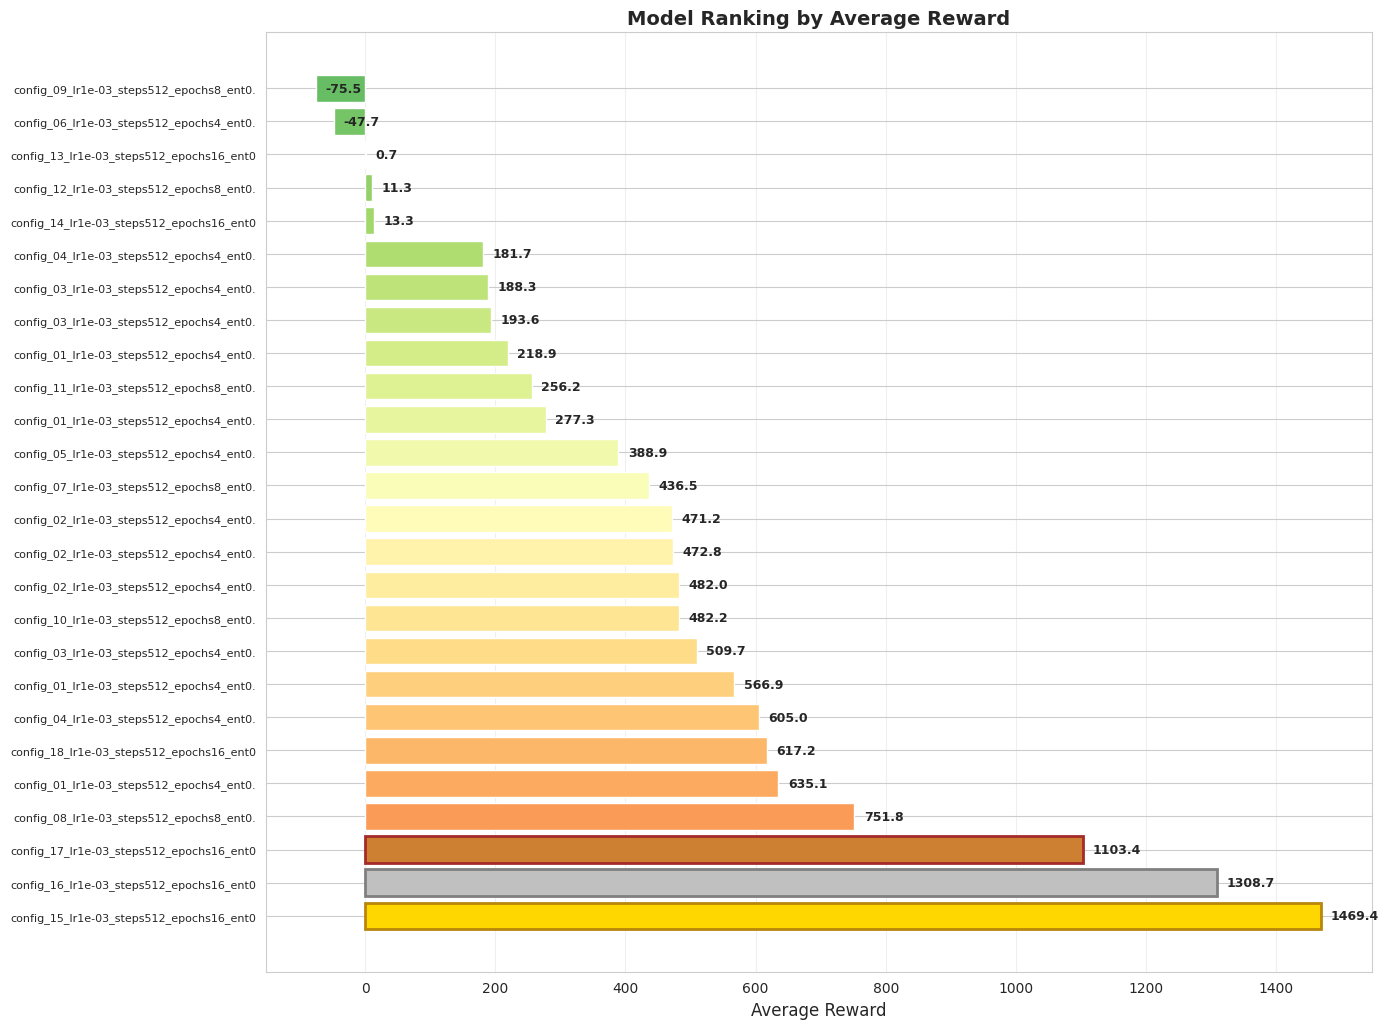

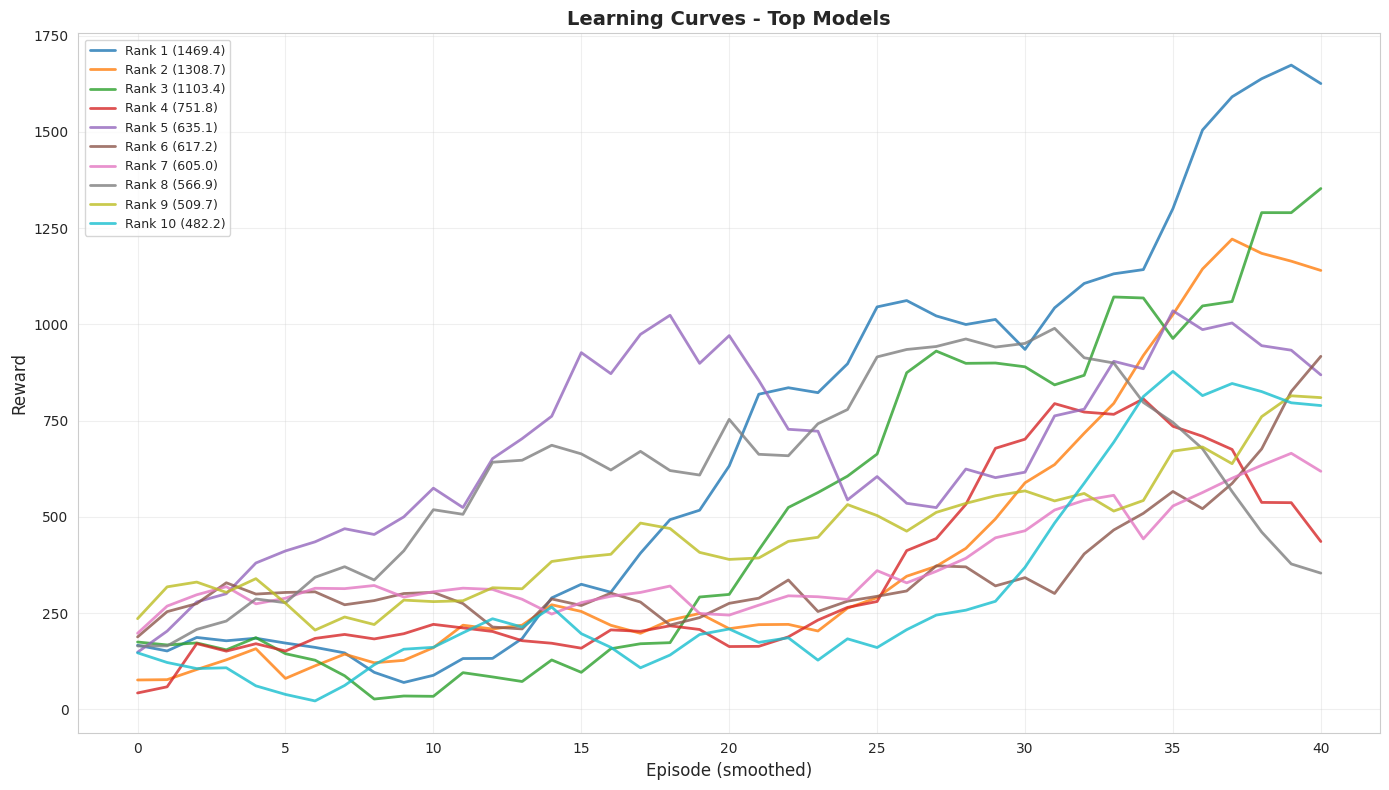

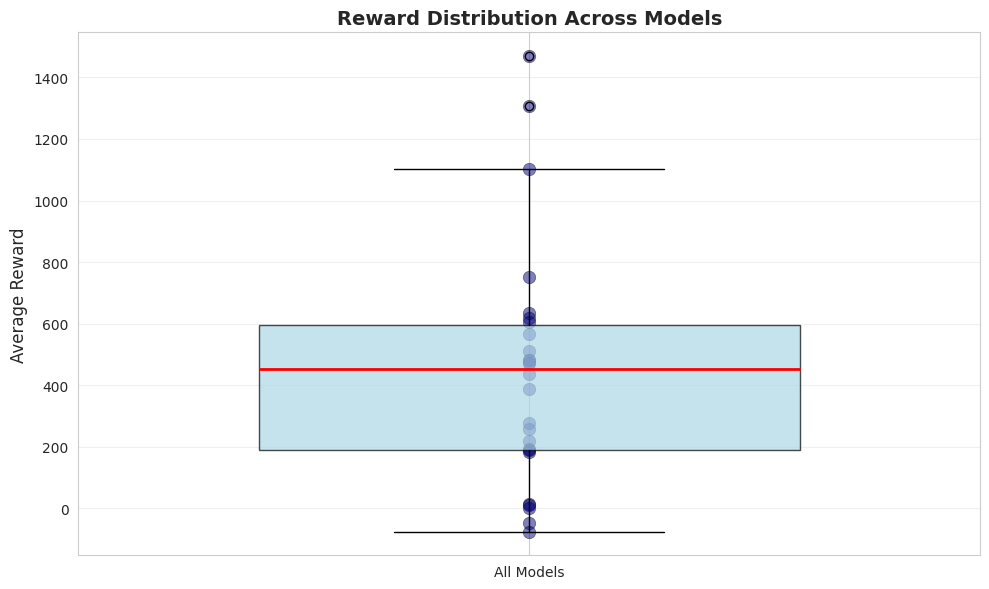

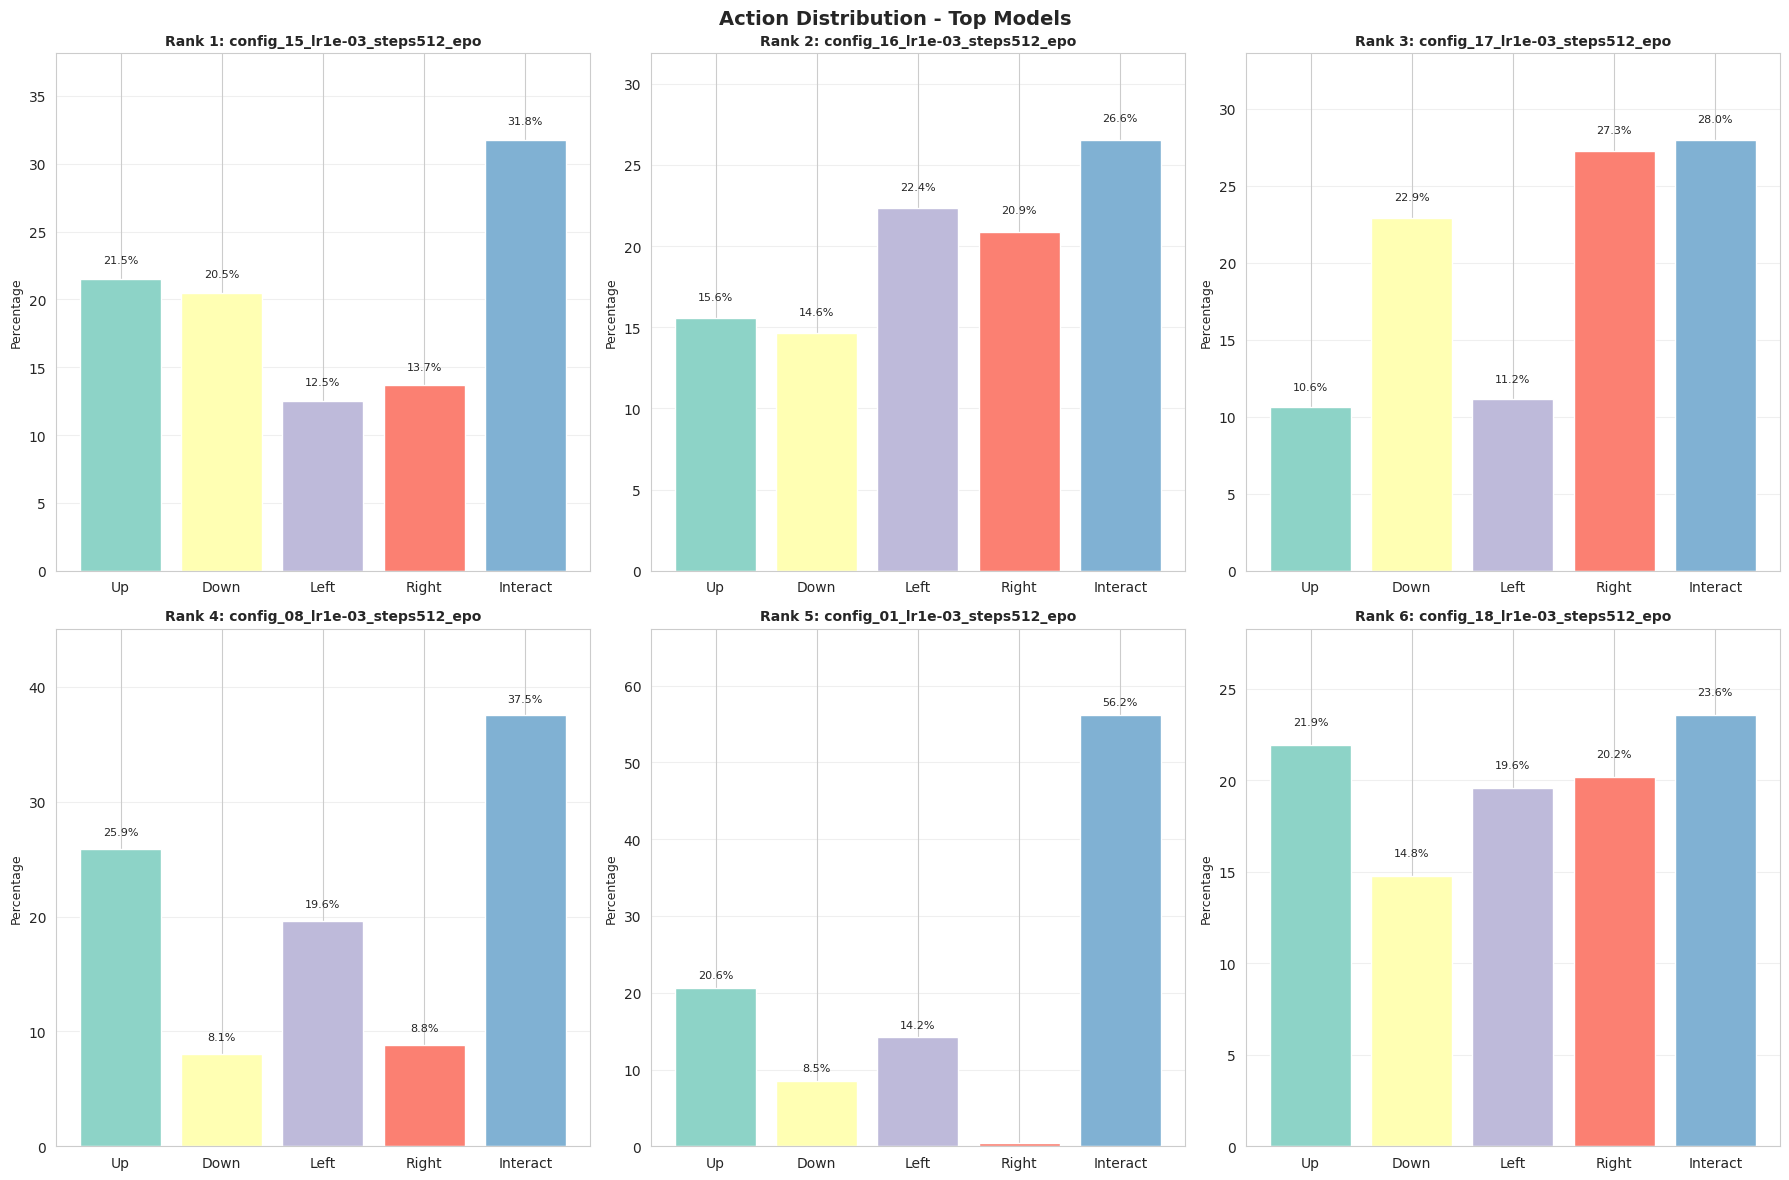

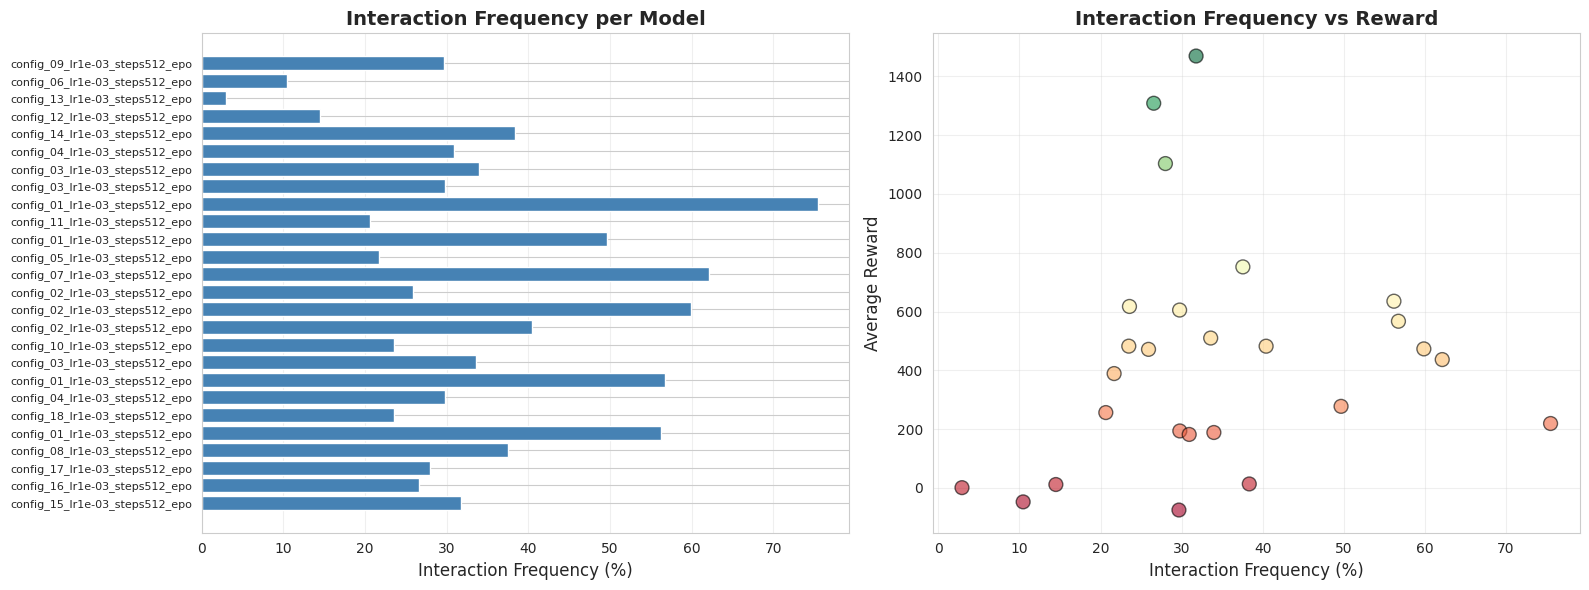

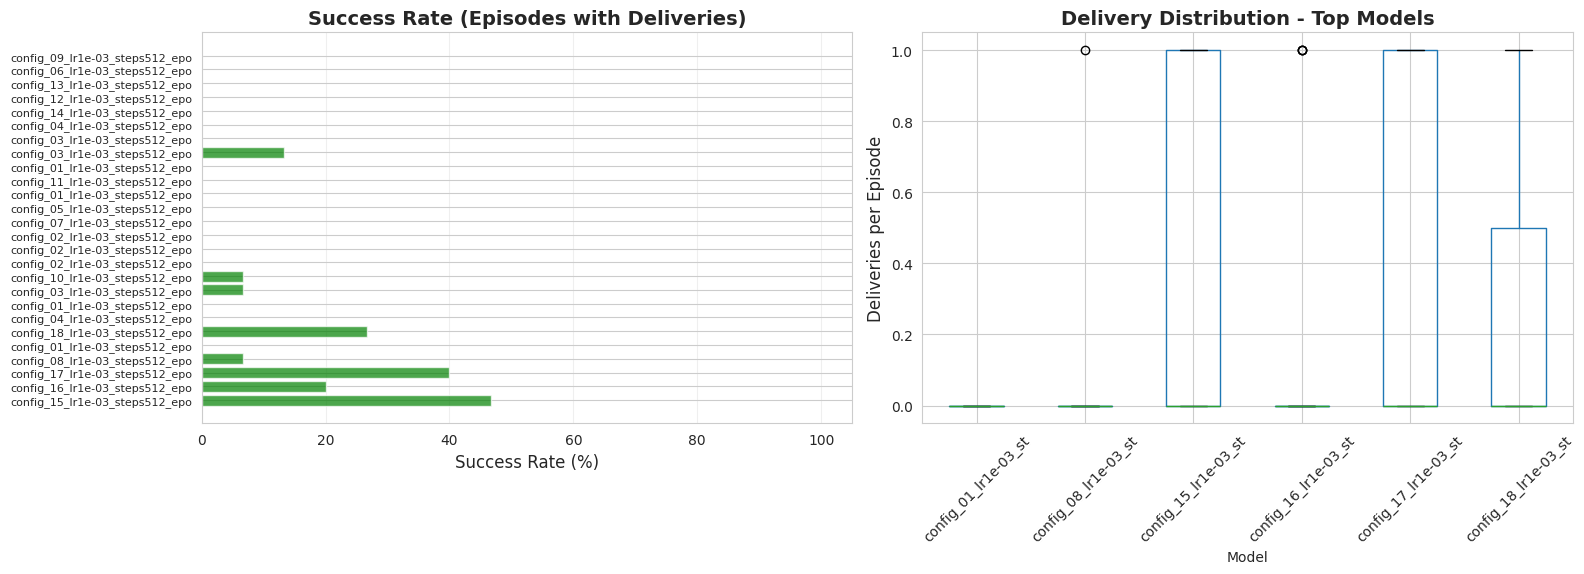

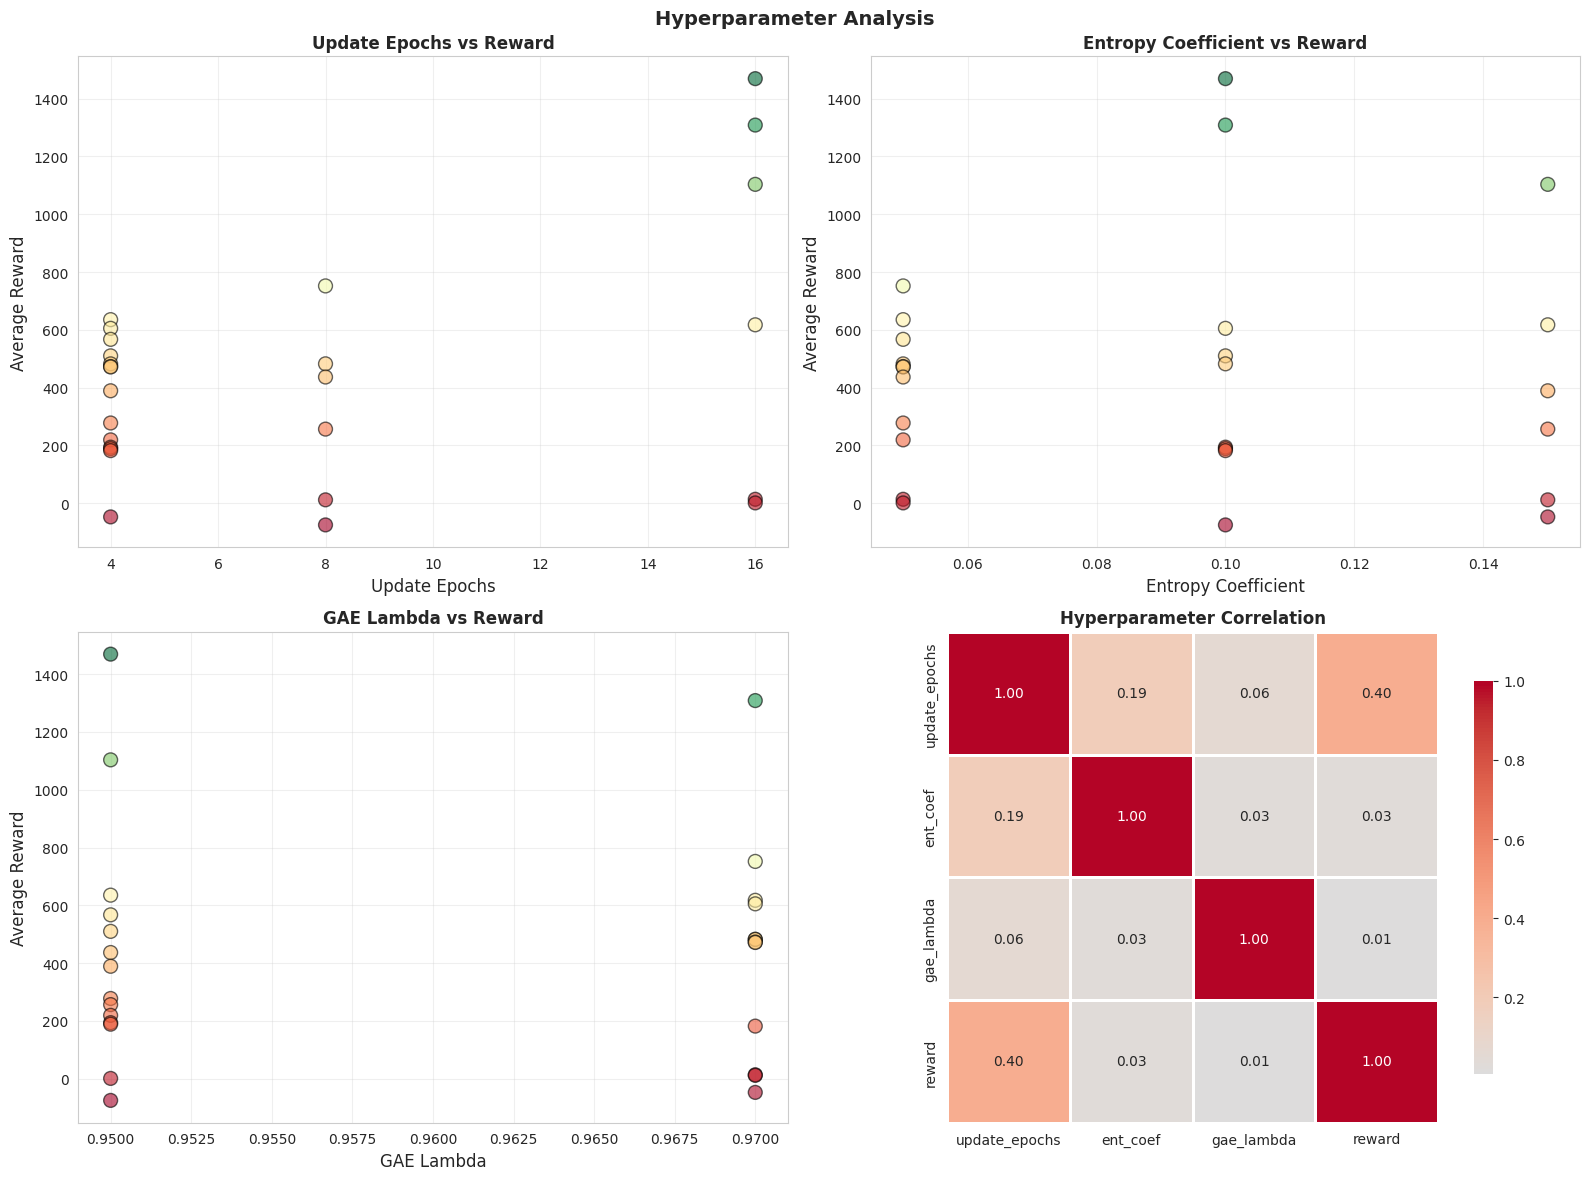

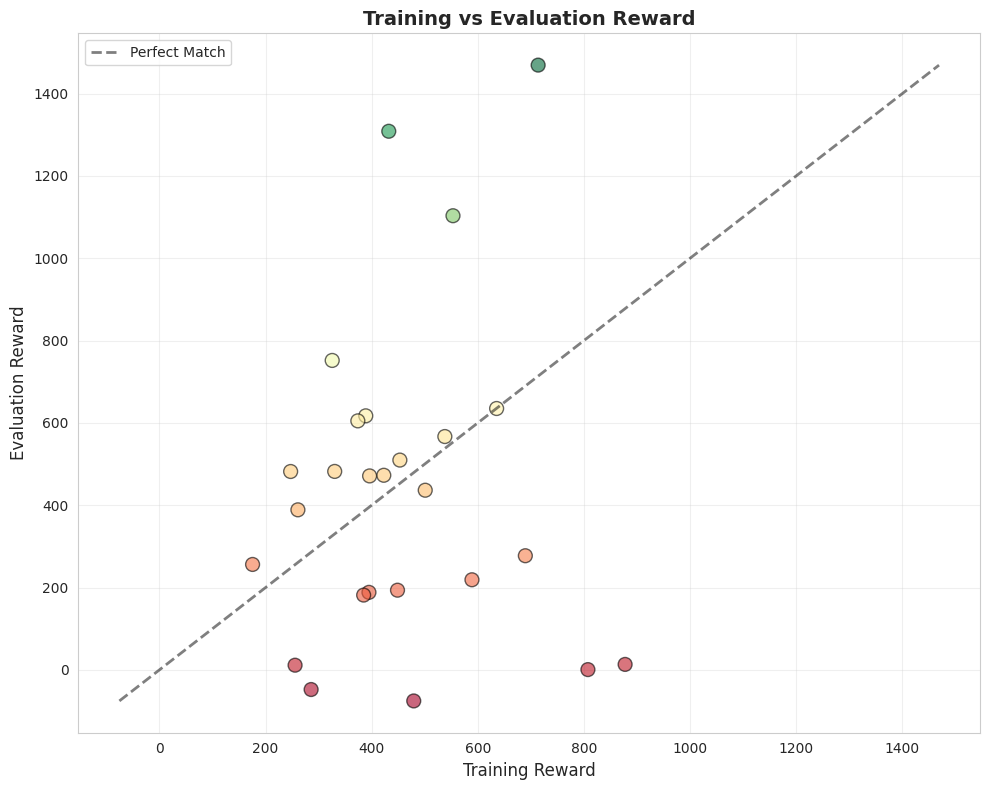

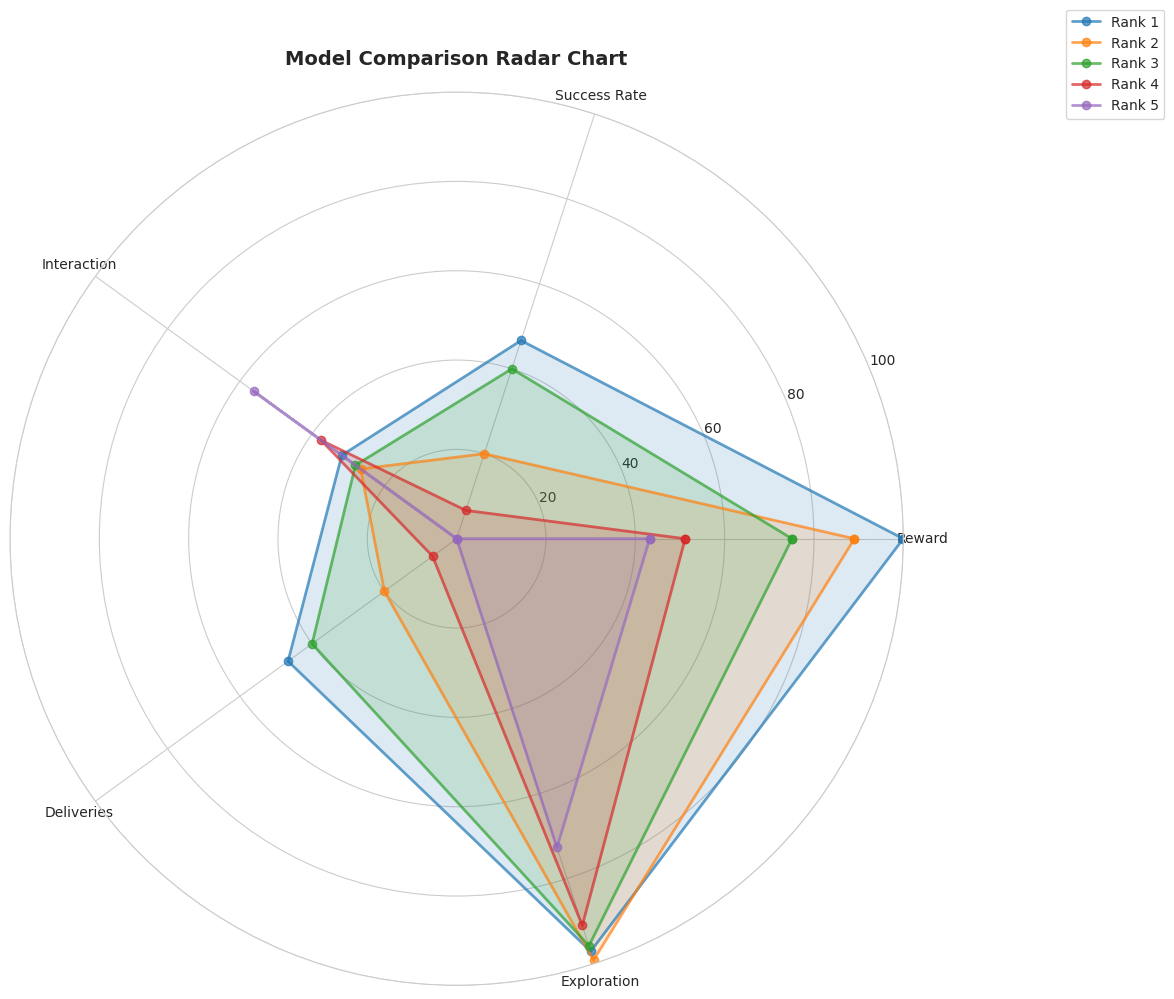


Analysis plots saved to analysis_output/


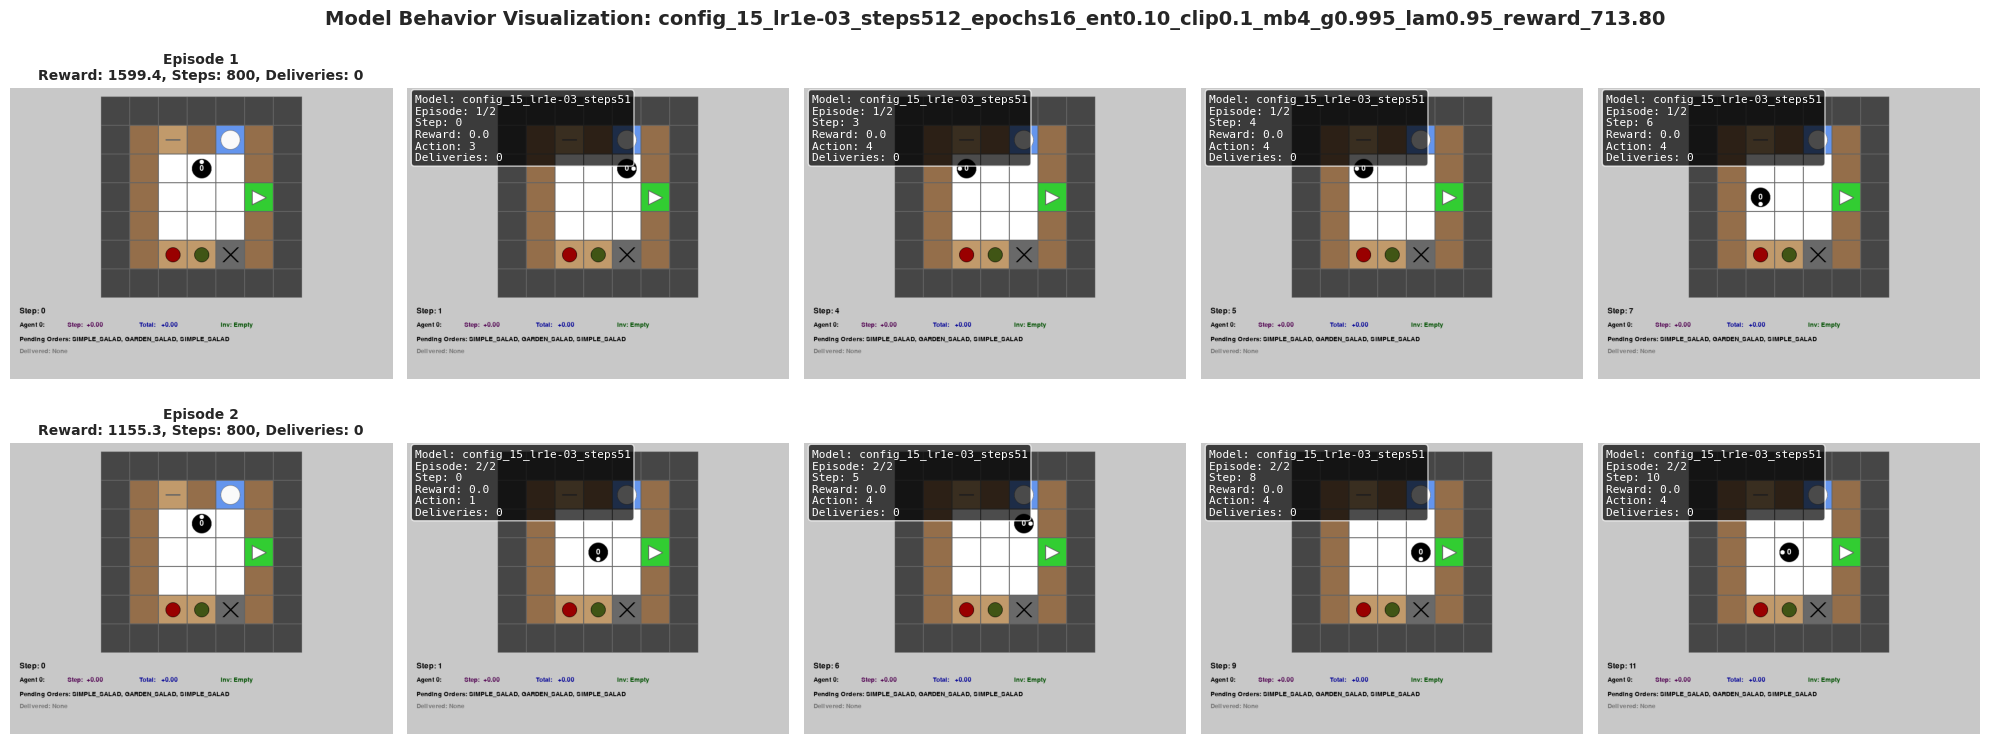

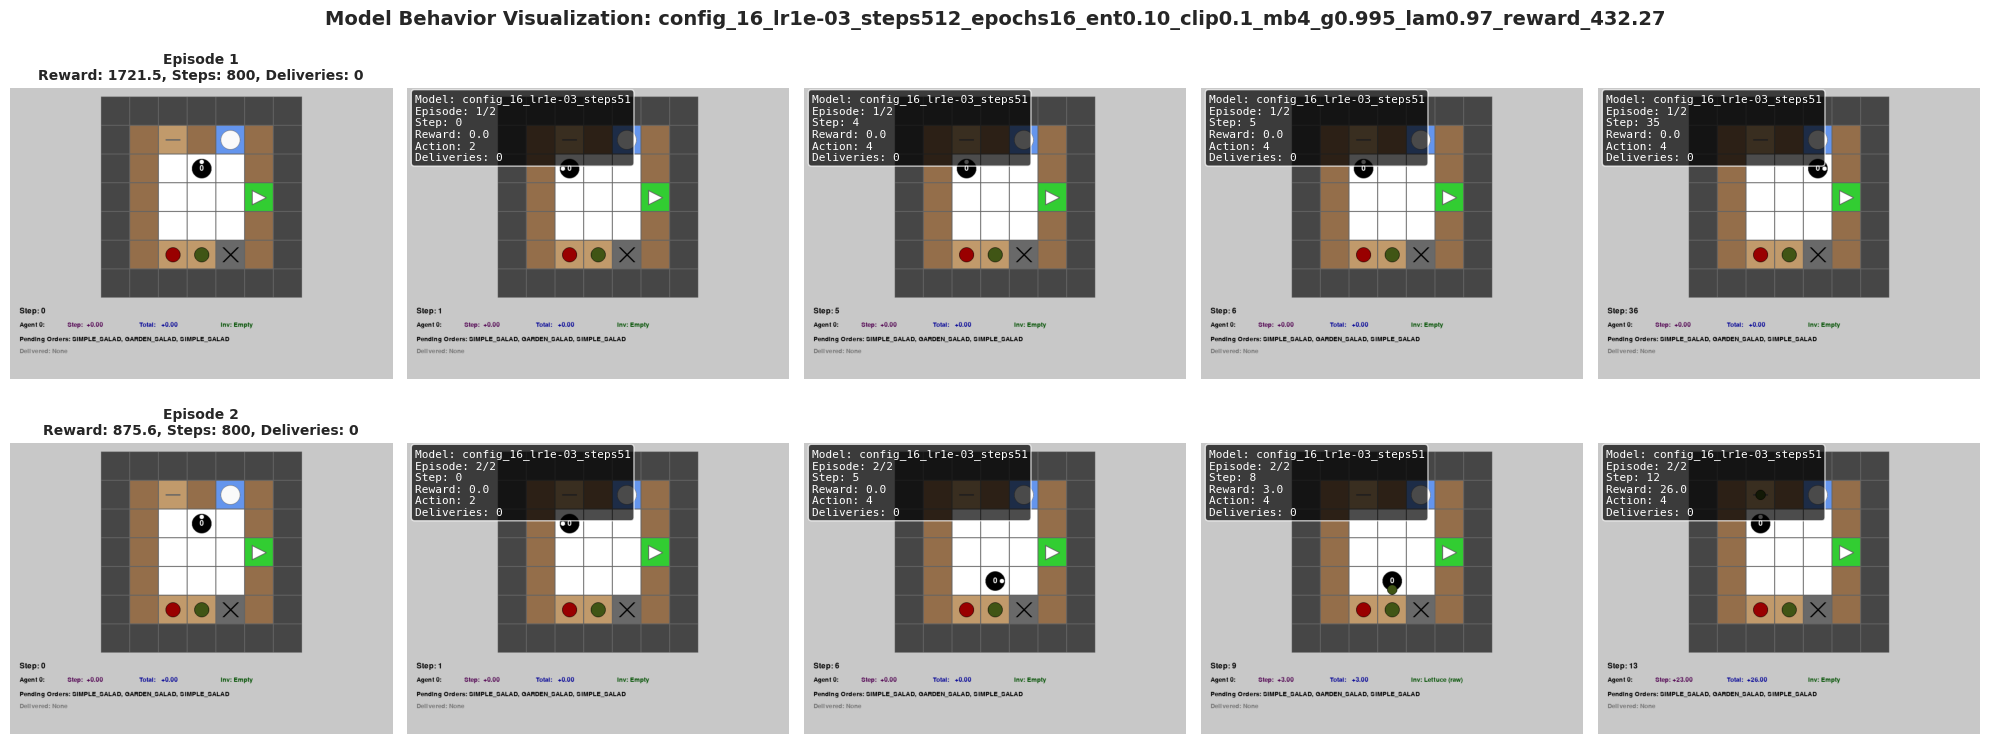

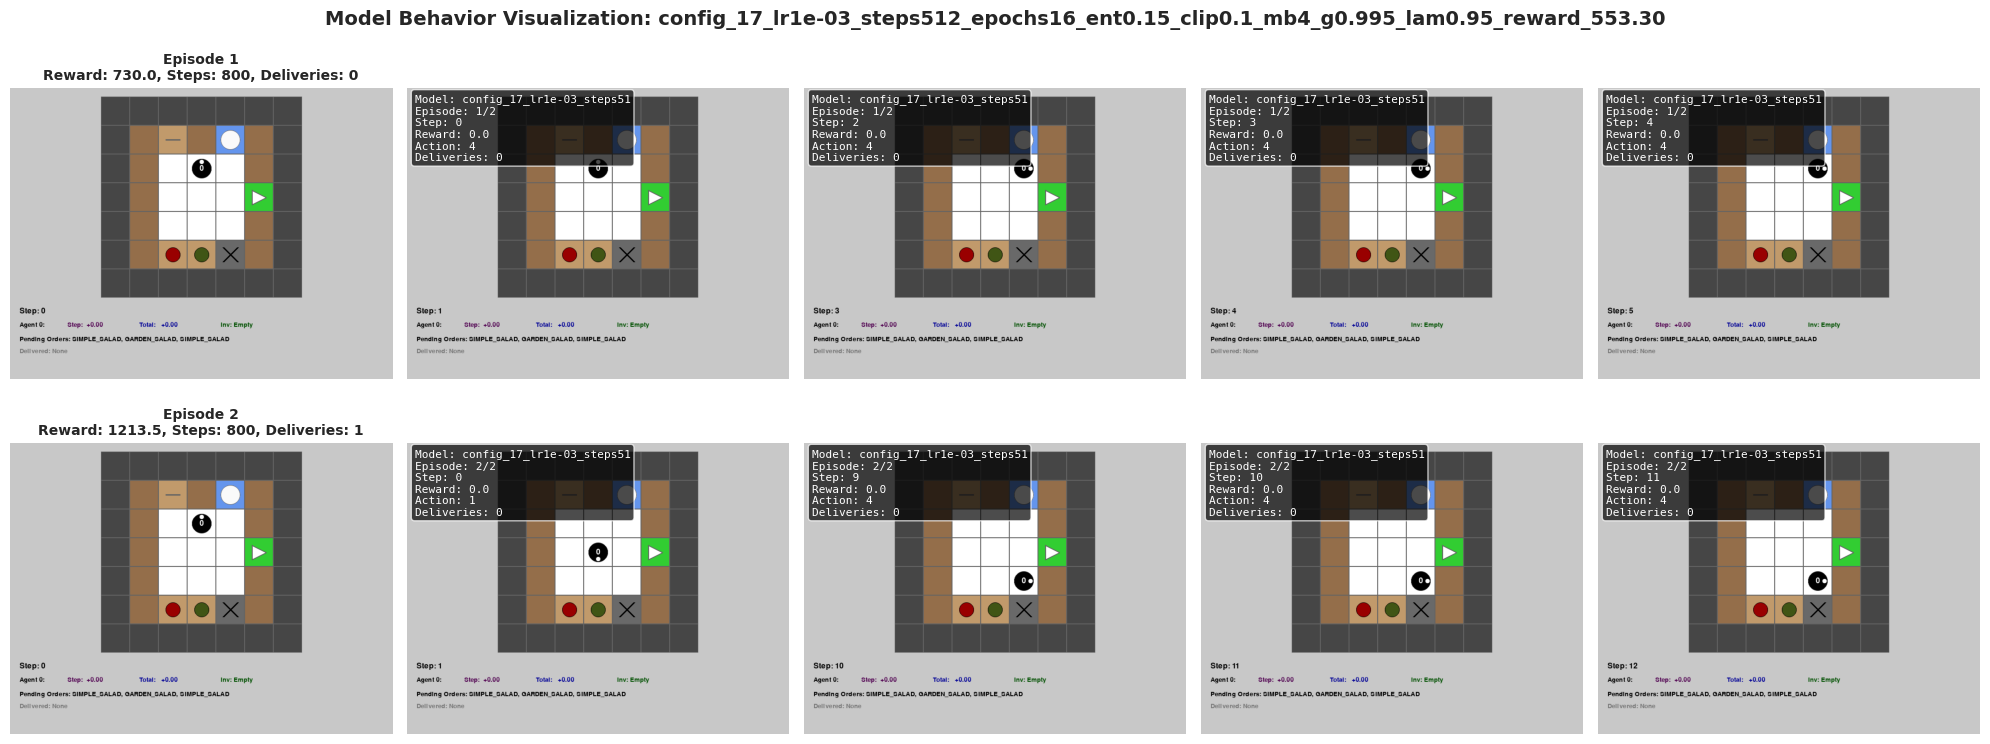


EVALUATION SUMMARY

Top 5 Models:
1. config_15_lr1e-03_steps512_epochs16_ent0.10_clip0.
   Reward: 1469.36 ± 449.31
   Success Rate: 46.7%
   Avg Deliveries: 0.47
   Interaction Freq: 31.8%

2. config_16_lr1e-03_steps512_epochs16_ent0.10_clip0.
   Reward: 1308.66 ± 310.10
   Success Rate: 20.0%
   Avg Deliveries: 0.20
   Interaction Freq: 26.6%

3. config_17_lr1e-03_steps512_epochs16_ent0.15_clip0.
   Reward: 1103.44 ± 473.08
   Success Rate: 40.0%
   Avg Deliveries: 0.40
   Interaction Freq: 28.0%

4. config_08_lr1e-03_steps512_epochs8_ent0.05_clip0.1
   Reward: 751.84 ± 365.58
   Success Rate: 6.7%
   Avg Deliveries: 0.07
   Interaction Freq: 37.5%

5. config_01_lr1e-03_steps512_epochs4_ent0.05_clip0.1
   Reward: 635.07 ± 239.88
   Success Rate: 0.0%
   Avg Deliveries: 0.00
   Interaction Freq: 56.2%

All plots and visualizations saved to: analysis_output/


In [7]:
# Discover models
model_paths = discover_models()
print(f"Found {len(model_paths)} models")

if not model_paths:
    print("No models found in models/ directory")
else:
    # Evaluate all models
    evaluation_results = []
    
    for model_path in tqdm(model_paths, desc="Evaluating"):
        result = evaluate_model(model_path, num_episodes=15)
        if result:
            evaluation_results.append(result)
    
    if evaluation_results:
        # Generate analysis plots
        generate_analysis_plots(evaluation_results)
        
        # Visualize top models
        df = pd.DataFrame(evaluation_results)
        df = df.sort_values('mean_reward', ascending=False)
        top_models = df.head(3)
        
        for _, row in top_models.iterrows():
            model_path = Path(row['model_path'])
            visualize_model_behavior(model_path, num_episodes=2, save_frames=True)
        
        # Summary
        print("\n" + "=" * 70)
        print("EVALUATION SUMMARY")
        print("=" * 70)
        df_summary = pd.DataFrame(evaluation_results)
        df_summary = df_summary.sort_values('mean_reward', ascending=False)
        
        print("\nTop 5 Models:")
        for i, (_, row) in enumerate(df_summary.head(5).iterrows(), 1):
            print(f"{i}. {row['filename'][:50]}")
            print(f"   Reward: {row['mean_reward']:.2f} ± {row['std_reward']:.2f}")
            print(f"   Success Rate: {row['success_rate']*100:.1f}%")
            print(f"   Avg Deliveries: {row['mean_deliveries']:.2f}")
            print(f"   Interaction Freq: {row['interaction_frequency']*100:.1f}%")
            print()
        
        print(f"All plots and visualizations saved to: {OUTPUT_DIR}/")
